# Single layer — digitised benchmark and observations

Hudleston's single competent layer in a weak matrix (viscosity ratio 24:1,
his Fig. 3A), digitised from `data/single_layer_digitised.svg`. This notebook
makes everything the fits use:

1. the **ground truth** from Layer 2 of the SVG: six contacts, bedding normals
   and the strain of each originally square marker cell, written to
   `data/single_layer_ground_truth.npz`;
2. the **sparse observations** the inversions see: ten points per contact, ten
   signed bedding normals, and the split of the marker cells into those used in
   the fit and those held out, written to `data/single_layer_observations.npz`.

`03b_single_layer_fit` fits one LDI model without and one with strain to tune
the settings,
`03c_single_layer_ensemble` fits the ensembles with them and
`03d_single_layer_figures` draws them; all read these files through
`single_layer_inputs.py`.

---

Only **Layer 2** of the SVG is read. Layer 2 has two families of curves. A
curve is a **horizon** when its $x$ extent is at least its $y$ extent; the
steeper curves are kept only so their crossings can be found.

A **gradient** is not one of those curves. It is a point on a horizon and a
direction read from that horizon: the unit tangent along the trace, rotated
$90^\circ$ counter-clockwise. Each horizon is oriented left to right first, so
on a flat bed the normal points upward.

Coordinates stay in SVG user units, with $y$ flipped by the viewBox height so
that up on the plot is up on the section.

In [1]:
from pathlib import Path
import xml.etree.ElementTree as ET

import matplotlib.pyplot as plt
import numpy as np
from svgpathtools import parse_path

N_SAMPLES = 400


def svg_path() -> Path:
    for candidate in (
        Path("data/single_layer_digitised.svg"),
    ):
        if candidate.exists():
            return candidate
    raise FileNotFoundError("single_layer_digitised.svg not found")


def _local(tag: str) -> str:
    return tag.split("}")[-1]


def _sample(path, n: int) -> np.ndarray:
    pts = np.empty((n, 2))
    for k, t in enumerate(np.linspace(0.0, 1.0, n)):
        z = path.point(float(t))
        pts[k, 0] = z.real
        pts[k, 1] = z.imag
    return pts


def load_layer2(path: Path, n_samples: int = N_SAMPLES):
    """Return Layer 2 curves as dicts with a parsed path and a y-up polyline."""
    root = ET.parse(path).getroot()
    view = root.get("viewBox").replace(",", " ").split()
    svg_h = float(view[3])

    layer = next(
        (el for el in root.iter() if _local(el.tag) == "g" and el.get("id") == "Layer_2"),
        None,
    )
    if layer is None:
        raise ValueError("Layer_2 not found")

    curves = []
    for el in list(layer):
        if _local(el.tag) != "path" or not el.get("d"):
            continue
        sp = parse_path(el.get("d"))
        if sp.length() == 0:
            continue
        pts = _sample(sp, n_samples)
        pts[:, 1] = svg_h - pts[:, 1]
        dx = float(np.ptp(pts[:, 0]))
        dy = float(np.ptp(pts[:, 1]))
        curves.append({
            "path": sp,
            "pts": pts,
            "dx": dx,
            "dy": dy,
            "kind": "horizon" if dx >= dy else "cross",
        })
    return curves, svg_h


def bedding_normal(pts: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Orient a horizon left to right and return its unit bedding normal.

    The normal is the unit tangent rotated 90 degrees counter-clockwise,
    so it points to the left of the direction of travel.
    """
    oriented = pts if pts[0, 0] <= pts[-1, 0] else pts[::-1].copy()
    tangent = np.empty_like(oriented)
    tangent[1:-1] = oriented[2:] - oriented[:-2]
    tangent[0] = oriented[1] - oriented[0]
    tangent[-1] = oriented[-1] - oriented[-2]
    length = np.linalg.norm(tangent, axis=1, keepdims=True).clip(min=1e-8)
    tangent = tangent / length
    normal = np.column_stack([-tangent[:, 1], tangent[:, 0]])
    return oriented, normal


def hit_xy(hit, svg_h: float) -> np.ndarray:
    z = hit[1].point(hit[2])
    return np.array([z.real, svg_h - z.imag])


## Horizons and gradients

Horizons are ordered from the bottom of the section upward. At every sample along a horizon, `gp` is the point and `gv` is the unit normal from `bedding_normal`.


In [2]:
SVG_PATH = svg_path()
curves, SVG_H = load_layer2(SVG_PATH)

horizons = [c for c in curves if c["kind"] == "horizon"]
crosses = [c for c in curves if c["kind"] == "cross"]
horizons.sort(key=lambda c: float(c["pts"][:, 1].mean()))
crosses.sort(key=lambda c: float(c["pts"][:, 0].mean()))

gp_parts, gv_parts, gh_parts = [], [], []
for i, h in enumerate(horizons):
    pts, normal = bedding_normal(h["pts"])
    h["pts"] = pts
    h["name"] = f"horizon {i}"
    gp_parts.append(pts)
    gv_parts.append(normal)
    gh_parts.append(np.full(len(pts), i, dtype=int))

for i, c in enumerate(crosses):
    c["name"] = f"cross {i}"

gp = np.vstack(gp_parts)
gv = np.vstack(gv_parts)
gradient_horizon = np.concatenate(gh_parts)
ordered = horizons + crosses

print(f"file: {SVG_PATH}")
print(f"Layer 2 curves: {len(curves)}  ({len(horizons)} horizons, {len(crosses)} cross curves)")
print(f"gradients: gp {gp.shape}, gv {gv.shape}")
print(f"  |gv| mean {np.linalg.norm(gv, axis=1).mean():.3f}")
for h in horizons:
    m = gradient_horizon == int(h["name"].split()[-1])
    print(
        f"  {h['name']}: {m.sum()} points, "
        f"mean normal ({gv[m, 0].mean():+.2f}, {gv[m, 1].mean():+.2f})"
    )


file: data/single_layer_digitised.svg
Layer 2 curves: 27  (6 horizons, 21 cross curves)
gradients: gp (2400, 2), gv (2400, 2)
  |gv| mean 1.000
  horizon 0: 400 points, mean normal (+0.11, +0.96)
  horizon 1: 400 points, mean normal (+0.07, +0.88)
  horizon 2: 400 points, mean normal (+0.03, +0.73)
  horizon 3: 400 points, mean normal (+0.04, +0.71)
  horizon 4: 400 points, mean normal (+0.10, +0.90)
  horizon 5: 400 points, mean normal (+0.11, +0.97)


## Intersections

Every pair of Layer 2 curves is tested, horizons and cross curves together. A hit is the point where the two Bézier paths cross. If the same pair reports the same location again (within one SVG unit), the copy is dropped.


In [3]:
TOL = 1.0

intersections = []
for i in range(len(ordered)):
    for j in range(i + 1, len(ordered)):
        for ha, _hb in ordered[i]["path"].intersect(ordered[j]["path"]):
            xy = hit_xy(ha, SVG_H)
            duplicate = any(
                rec["i"] == i
                and rec["j"] == j
                and np.linalg.norm(rec["xy"] - xy) < TOL
                for rec in intersections
            )
            if duplicate:
                continue
            intersections.append({
                "i": i,
                "j": j,
                "name_i": ordered[i]["name"],
                "name_j": ordered[j]["name"],
                "kind_i": ordered[i]["kind"],
                "kind_j": ordered[j]["kind"],
                "xy": xy,
            })

xy = np.vstack([rec["xy"] for rec in intersections]) if intersections else np.zeros((0, 2))

n_hh = sum(r["kind_i"] == "horizon" and r["kind_j"] == "horizon" for r in intersections)
n_cc = sum(r["kind_i"] == "cross" and r["kind_j"] == "cross" for r in intersections)
n_hc = len(intersections) - n_hh - n_cc

print(f"unique intersections: {len(intersections)}")
print(f"  horizon–horizon: {n_hh}")
print(f"  cross–cross: {n_cc}")
print(f"  horizon–cross: {n_hc}")
print()
for h in horizons:
    n = sum(
        (r["name_i"] == h["name"]) or (r["name_j"] == h["name"])
        for r in intersections
    )
    print(f"  {h['name']}: {n} intersections")


unique intersections: 126
  horizon–horizon: 0
  cross–cross: 0
  horizon–cross: 126

  horizon 0: 21 intersections
  horizon 1: 21 intersections
  horizon 2: 21 intersections
  horizon 3: 21 intersections
  horizon 4: 21 intersections
  horizon 5: 21 intersections


## Cut the horizons to the verticals

The digitised horizons run past the first and last vertical line. A horizon is cut
where it crosses the **first** and the **last** vertical, so its end points are
those two crossings and the trace between them is sampled again at `N_SAMPLES`
points along the curve. The gradients (`gp`, `gv`) are rebuilt on the cut traces,
with the normals read from the cut trace, so the observations below, the scoring
traces and the restored contacts all cover the same extent. Run this before
anything that reads `horizons`, `gp` or `gv`.

In [4]:
def crossing_T(path, other):
    """Parameter along `path` of its crossing with `other` (exactly one is expected)."""
    hits = path.intersect(other)
    xys = [hit_xy(ha, SVG_H) for ha, _hb in hits]
    if not hits or max(np.linalg.norm(p - xys[0]) for p in xys) > TOL:
        raise ValueError("a horizon does not cross a vertical exactly once")
    return float(hits[0][0][0])


first_vertical, last_vertical = crosses[0], crosses[-1]    # crosses are sorted left to right
gp_parts, gv_parts, gh_parts = [], [], []
for i, h in enumerate(horizons):
    t_a, t_b = sorted((crossing_T(h["path"], first_vertical["path"]),
                       crossing_T(h["path"], last_vertical["path"])))
    cut = np.empty((N_SAMPLES, 2))
    for k, t in enumerate(np.linspace(t_a, t_b, N_SAMPLES)):
        z = h["path"].point(float(t))
        cut[k] = (z.real, SVG_H - z.imag)
    n_before = len(h["pts"])
    x_before = (float(h["pts"][:, 0].min()), float(h["pts"][:, 0].max()))
    h["pts"], normal = bedding_normal(cut)
    gp_parts.append(h["pts"])
    gv_parts.append(normal)
    gh_parts.append(np.full(len(h["pts"]), i, dtype=int))
    print(f"  {h['name']}: x {x_before[0]:.0f}..{x_before[1]:.0f} -> "
          f"{h['pts'][:, 0].min():.0f}..{h['pts'][:, 0].max():.0f}")

gp = np.vstack(gp_parts)
gv = np.vstack(gv_parts)
gradient_horizon = np.concatenate(gh_parts)
print(f"gradients: gp {gp.shape}, gv {gv.shape}")

  horizon 0: x 669..1137 -> 678..1129
  horizon 1: x 639..1145 -> 654..1134
  horizon 2: x 614..1168 -> 629..1145
  horizon 3: x 627..1150 -> 643..1132
  horizon 4: x 634..1133 -> 656..1125
  horizon 5: x 656..1134 -> 664..1120
gradients: gp (2400, 2), gv (2400, 2)


## Plot

Coloured traces are the horizons. Arrows are the bedding normals `gv` at points on those traces (drawn at every 20th sample). Grey curves are the cross curves, and the black points are their intersections with the horizons.


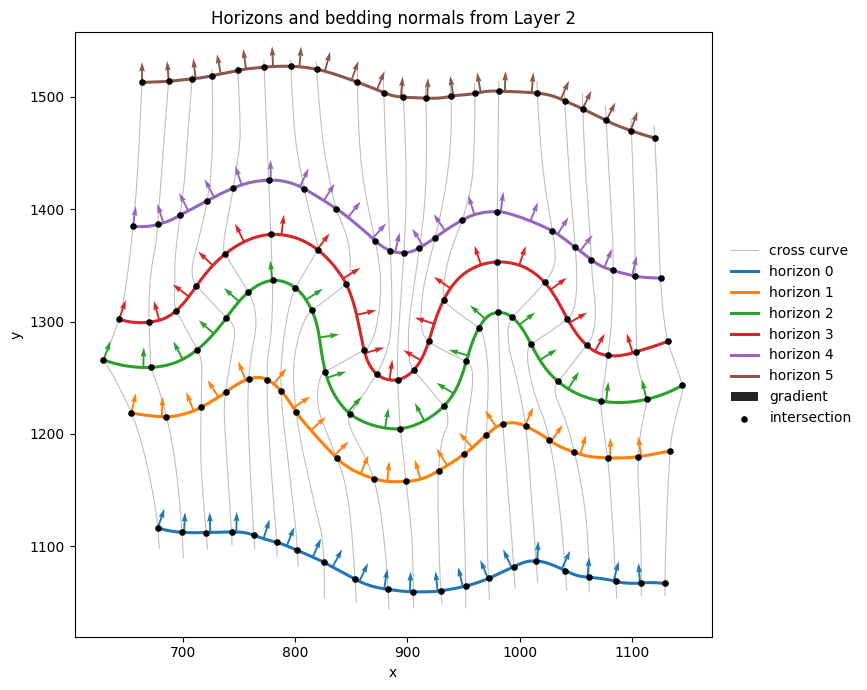

In [5]:
colors = plt.cm.tab10.colors
step = 20
arrow = 18.0

fig, ax = plt.subplots(figsize=(9, 7))

for c in crosses:
    ax.plot(c["pts"][:, 0], c["pts"][:, 1], color="0.75", lw=0.8, zorder=1)
ax.plot([], [], color="0.75", lw=0.8, label="cross curve")

for k, h in enumerate(horizons):
    color = colors[k % len(colors)]
    ax.plot(
        h["pts"][:, 0], h["pts"][:, 1],
        color=color, lw=2.2, zorder=3, label=h["name"],
    )
    m = np.flatnonzero(gradient_horizon == k)[::step]
    ax.quiver(
        gp[m, 0], gp[m, 1], gv[m, 0], gv[m, 1],
        angles="xy", scale_units="xy", scale=1.0 / arrow,
        color=color, width=0.003, zorder=4,
    )

ax.quiver([], [], [], [], color="0.15", scale=1, label="gradient")

if len(xy):
    ax.scatter(xy[:, 0], xy[:, 1], s=14, c="black", zorder=5, label="intersection")

ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Horizons and bedding normals from Layer 2")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
fig.tight_layout()
plt.show()


## Strain from originally square cells

Take two neighbouring crossings on one horizon and the two crossings of the same cross-curves on the horizon below. Those four points are one cell of the grid.

The cell is treated as the image of a square. The square's horizontal side maps to the mean of the two edges that run along the horizons, and its vertical side maps to the mean of the two edges that run from the lower horizon to the upper one. That pair of vectors is the Jacobian of the bilinear map at the cell centre.

The original side length is the same for every cell and is not fixed by the drawing. It is chosen so the median cell keeps its area (`median det F = 1`). The ratio of the principal stretches does not depend on that choice. `F` is the deformation matrix in the present-day coordinates. The strain ellipse drawn on the section is the spatial one, from `B = F Fᵀ`. The Green–Lagrange tensor `E = (Fᵀ F − I) / 2` is the same stretch written in the reference square.


In [6]:
def crossing_grid(records):
    """Map (horizon, cross) to the unique crossing of that pair."""
    grid = {}
    for rec in records:
        if {rec["kind_i"], rec["kind_j"]} != {"horizon", "cross"}:
            continue
        if rec["kind_i"] == "horizon":
            h = int(rec["name_i"].split()[-1])
            c = int(rec["name_j"].split()[-1])
        else:
            h = int(rec["name_j"].split()[-1])
            c = int(rec["name_i"].split()[-1])
        grid[(h, c)] = np.asarray(rec["xy"], dtype=float)
    return grid


def cell_strain(grid, n_horizons, n_crosses):
    """Deformation of each grid cell from an originally square marker.

    Horizons are indexed bottom to top, cross-curves left to right. Cell
    (h, c) uses horizons h and h+1 and cross-curves c and c+1.
    """
    edges = []
    centres = []
    index = []
    for h in range(n_horizons - 1):
        for c in range(n_crosses - 1):
            bl = grid[(h, c)]
            br = grid[(h, c + 1)]
            tl = grid[(h + 1, c)]
            tr = grid[(h + 1, c + 1)]
            along = 0.5 * ((br - bl) + (tr - tl))
            across = 0.5 * ((tl - bl) + (tr - br))
            edges.append(np.column_stack([along, across]))
            centres.append(0.25 * (bl + br + tl + tr))
            index.append((h, c))

    J = np.stack(edges)                         # (N, 2, 2), columns are edge vectors
    area = np.linalg.det(J)
    if np.any(area <= 0):
        raise ValueError("a cell has non-positive area")
    side = float(np.sqrt(np.median(area)))      # one original square for the whole grid
    F = J / side

    B = F @ np.swapaxes(F, -1, -2)              # spatial, F F^T
    C = np.swapaxes(F, -1, -2) @ F              # material, F^T F
    evals, evecs = np.linalg.eigh(B)            # ascending
    stretches = np.sqrt(np.clip(evals, 1e-12, None))
    E = 0.5 * (C - np.eye(2))

    return {
        "horizon": np.array([h for h, _ in index]),
        "cross": np.array([c for _, c in index]),
        "centre": np.stack(centres),
        "F": F,
        "E": E,
        "stretch": stretches,                   # λ1 <= λ2, spatial
        "axis": evecs,                          # columns are spatial principal directions
        "area_ratio": area / side**2,
        "side": side,
    }


grid = crossing_grid(intersections)
strain = cell_strain(grid, len(horizons), len(crosses))
ratio = strain["stretch"][:, 1] / strain["stretch"][:, 0]

print(f"cells: {len(strain['centre'])}  ({len(horizons) - 1} horizon pairs × {len(crosses) - 1} cross pairs)")
print(f"original side: {strain['side']:.2f}")
print(f"det F:  min {strain['area_ratio'].min():.3f}  median {np.median(strain['area_ratio']):.3f}  max {strain['area_ratio'].max():.3f}")
print(f"λ2/λ1: min {ratio.min():.3f}  median {np.median(ratio):.3f}  max {ratio.max():.3f}")
print()
for h in range(len(horizons) - 1):
    m = strain["horizon"] == h
    print(
        f"  horizons {h}–{h + 1}: "
        f"λ2/λ1 median {np.median(ratio[m]):.2f}  "
        f"det F median {np.median(strain['area_ratio'][m]):.2f}"
    )


cells: 100  (5 horizon pairs × 20 cross pairs)
original side: 42.66
det F:  min 0.659  median 1.000  max 2.613
λ2/λ1: min 1.125  median 4.173  max 9.757

  horizons 0–1: λ2/λ1 median 5.13  det F median 1.45
  horizons 1–2: λ2/λ1 median 4.17  det F median 0.86
  horizons 2–3: λ2/λ1 median 1.26  det F median 0.74
  horizons 3–4: λ2/λ1 median 3.76  det F median 0.86
  horizons 4–5: λ2/λ1 median 5.85  det F median 1.46


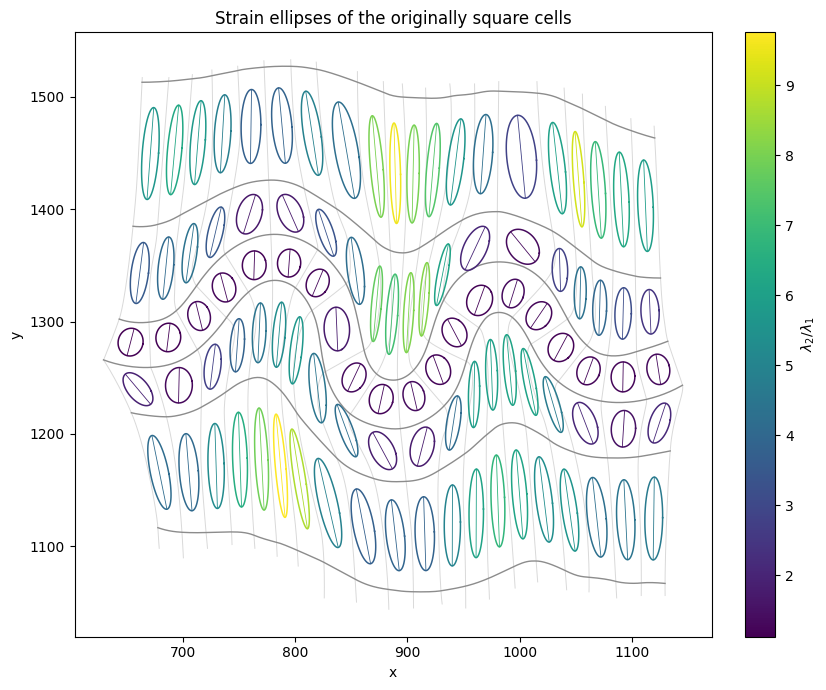

In [7]:
fig, ax = plt.subplots(figsize=(9, 7))

for c in crosses:
    ax.plot(c["pts"][:, 0], c["pts"][:, 1], color="0.85", lw=0.7, zorder=1)
for k, h in enumerate(horizons):
    ax.plot(h["pts"][:, 0], h["pts"][:, 1], color="0.55", lw=1.0, zorder=2)

theta = np.linspace(0, 2 * np.pi, 80)
circle = np.stack([np.cos(theta), np.sin(theta)])
radius = 0.32 * strain["side"]
norm = plt.Normalize(vmin=ratio.min(), vmax=ratio.max())
cmap = plt.cm.viridis

for i in range(len(ratio)):
    ell = strain["centre"][i][:, None] + radius * (strain["F"][i] @ circle)
    ax.plot(ell[0], ell[1], color=cmap(norm(ratio[i])), lw=1.1, zorder=3)
    long = strain["axis"][i, :, 1] * strain["stretch"][i, 1] * radius
    ctr = strain["centre"][i]
    ax.plot(
        [ctr[0] - long[0], ctr[0] + long[0]],
        [ctr[1] - long[1], ctr[1] + long[1]],
        color=cmap(norm(ratio[i])), lw=0.6, zorder=3,
    )

sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.04, label=r"$\lambda_2/\lambda_1$")

ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Strain ellipses of the originally square cells")
fig.tight_layout()
plt.show()


## Ground truth

The horizons, vertical lines, unit bedding normals, and strain ellipses are written to `data/single_layer_ground_truth.npz`. Horizon and vertical-line ids follow the order used above (horizons bottom to top, vertical lines left to right). Strain eigenvectors are the spatial principal directions of $B = FF^{\mathsf{T}}$, minor then major, and `strain_eigenvalue_ratio` is the ratio of the corresponding eigenvalues of $B$.


In [8]:
out = Path("data/single_layer_ground_truth.npz")

horizon_xy = np.vstack([h["pts"] for h in horizons]).astype(np.float64)
horizon_id = np.concatenate([
    np.full(len(h["pts"]), i, dtype=np.int32) for i, h in enumerate(horizons)
])
vertical_xy = np.vstack([c["pts"] for c in crosses]).astype(np.float64)
vertical_id = np.concatenate([
    np.full(len(c["pts"]), i, dtype=np.int32) for i, c in enumerate(crosses)
])
gradient_xy = np.asarray(gp, dtype=np.float64)
gradient_vector = np.asarray(gv, dtype=np.float64)
strain_xy = np.asarray(strain["centre"], dtype=np.float64)
strain_eigenvectors = np.asarray(strain["axis"], dtype=np.float64)
strain_eigenvalue_ratio = (
    strain["stretch"][:, 1] ** 2 / strain["stretch"][:, 0] ** 2
).astype(np.float64)

np.savez(
    out,
    horizon_xy=horizon_xy,
    horizon_id=horizon_id,
    vertical_xy=vertical_xy,
    vertical_id=vertical_id,
    gradient_xy=gradient_xy,
    gradient_vector=gradient_vector,
    strain_xy=strain_xy,
    strain_eigenvectors=strain_eigenvectors,
    strain_eigenvalue_ratio=strain_eigenvalue_ratio,
)
print(f"wrote {out}")
print(f"  horizons {horizon_xy.shape} ids {np.unique(horizon_id).size}")
print(f"  vertical lines {vertical_xy.shape} ids {np.unique(vertical_id).size}")
print(f"  gradients {gradient_xy.shape} |v| {np.linalg.norm(gradient_vector, axis=1).mean():.3f}")
print(f"  strain {strain_xy.shape} ratio {strain_eigenvalue_ratio.min():.2f}–{strain_eigenvalue_ratio.max():.2f}")


wrote data/single_layer_ground_truth.npz
  horizons (2400, 2) ids 6
  vertical lines (8400, 2) ids 21
  gradients (2400, 2) |v| 1.000
  strain (100, 2) ratio 1.27–95.20


## Sparse observations

The inversions see ten points per contact and ten signed bedding normals,
drawn at random with `SEED`. Each contact keeps its two end points, the crossings with
the first and last vertical, and eight points drawn from between them. Twenty-five strain cells are chosen by
farthest-point sampling, so the strain observations cover the section rather
than forming a cluster; the other seventy-five are held out and used only to
score the fits.

Only indices are saved: `single_layer_inputs.load_observations` rebuilds the
observations from them and the ground truth, in the shifted frame with H0 at
the top.

In [21]:
import sys
sys.path.insert(0, str(Path("..").resolve()))  # publication/: figstyle, diagnostics
import figstyle
import single_layer_inputs

SEED = 42
N_HORIZON_SAMPLES = 10
N_GRADIENTS = 10
N_STRAIN_TRAIN = 15

truth = single_layer_inputs.load_truth()
rng = np.random.default_rng(SEED)
# Each contact keeps both its end points (where it meets the first and last vertical); the rest of
# its ten points are drawn at random from the points between them.
horizon_idx = np.stack([
    np.sort(np.concatenate([
        [0, len(trace) - 1],
        rng.choice(np.arange(1, len(trace) - 1), size=N_HORIZON_SAMPLES - 2, replace=False),
    ]))
    for trace in truth["horizons_full"]
])
gradient_idx = rng.choice(len(truth["gradient_xy"]), size=N_GRADIENTS, replace=False)
strain_train_idx = single_layer_inputs.farthest_point_indices(truth["strain_xy"], N_STRAIN_TRAIN, SEED + 1)
strain_test_idx = np.setdiff1d(np.arange(len(truth["strain_xy"])), strain_train_idx)

np.savez(
    Path("data") / single_layer_inputs.OBSERVATIONS,
    horizon_idx=horizon_idx, gradient_idx=gradient_idx,
    strain_train_idx=strain_train_idx, strain_test_idx=strain_test_idx, seed=SEED,
)
obs = single_layer_inputs.load_observations(truth)
print(f"contacts: {sum(map(len, obs['horizons']))} on {len(obs['horizons'])} horizons | "
      f"bedding: {len(obs['gp'])} | strain: {len(strain_train_idx)} in the fit, {len(strain_test_idx)} held out")

contacts: 60 on 6 horizons | bedding: 10 | strain: 15 in the fit, 85 held out


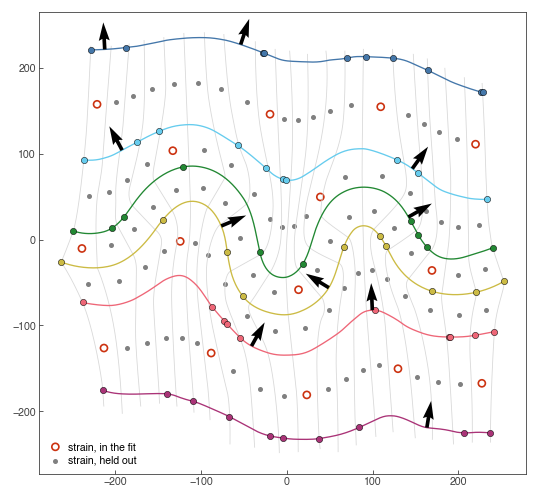

In [22]:
# Check: the observations on the section (not saved).
figstyle.apply()
colors = {n: figstyle.HORIZON_PALETTE[i % len(figstyle.HORIZON_PALETTE)]
          for i, n in enumerate(truth["horizon_names"])}
fig, ax = plt.subplots(figsize=(8, 5))
for trace in truth["verticals_full"]:
    ax.plot(trace[:, 0], trace[:, 1], color="0.85", lw=0.5)
for name, trace, pts in zip(truth["horizon_names"], truth["horizons_full"], obs["horizons"]):
    ax.plot(trace[:, 0], trace[:, 1], color=colors[name], lw=0.8)
    ax.scatter(pts[:, 0], pts[:, 1], s=14, color=colors[name], edgecolors="k", linewidths=0.3, zorder=3)
ax.quiver(obs["gp"][:, 0], obs["gp"][:, 1], obs["gv"][:, 0], obs["gv"][:, 1], color="k", zorder=4)
sxy = truth["strain_xy"]
ax.scatter(sxy[obs["strain_train_mask"], 0], sxy[obs["strain_train_mask"], 1], s=18, facecolors="none",
           edgecolors="#CC3311", label="strain, in the fit")
ax.scatter(sxy[~obs["strain_train_mask"], 0], sxy[~obs["strain_train_mask"], 1], s=4, color="0.5",
           label="strain, held out")
ax.set_aspect("equal")
ax.legend(loc="lower left", frameon=False)
plt.show()